# Simulated Radar TSPI Accuracy Analysis

### Project Objective

This project evaluates the positional accuracy of simulated radar tracking measurements against a simulated reference truth trajectory.

The analysis uses Python, pandas, NumPy, and Matplotlib to clean and align time-series data, calculate position errors, identify directional bias, and visualize tracking performance.

Both datasets are simulated for educational and portfolio purposes. Position coordinates are expressed in meters using a common East-North-Up (ENU) coordinate system, and timestamps are recorded in UTC.

In [101]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

#load data sets
data_folder = Path("../data")

truth = pd.read_csv(data_folder / "truth.csv")
radar = pd.read_csv(data_folder / "radar_raw.csv")

#check data set size
print("Truth:", truth.shape)
print("Radar:", radar.shape)

#preview our data sets
print("\nTruth preview:")
display(truth.head())
print("\nRadar preview:")
display(radar.head())



Truth: (301, 5)
Radar: (121, 5)

Truth preview:


,timestamp_utc,track_id,east_m,north_m,up_m
0,2026-01-15T15:00:00.000Z,SIM001,5000,8000.00,2200
1,2026-01-15T15:00:02.000Z,SIM001,5180,8070.14,2201
2,2026-01-15T15:00:04.000Z,SIM001,5360,8140.55,2202
3,2026-01-15T15:00:06.000Z,SIM001,5540,8211.23,2203
4,2026-01-15T15:00:08.000Z,SIM001,5720,8282.19,2204



Radar preview:


,timestamp_utc,track_id,east_m,north_m,up_m
0,2026-01-15T15:09:05.000Z,SIM001,54049.42,31924.07,NaN
1,2026-01-15T15:06:20.000Z,SIM001,39252.50,24791.15,2398.75
2,2026-01-15T15:01:20.000Z,SIM001,12226.15,10969.73,2228.98
3,2026-01-15T15:04:30.000Z,SIM001,29341.36,NaN,2337.72
4,2026-01-15T15:01:40.000Z,SIM001,14046.87,11852.82,2254.53


In [102]:
#checking column types
print("Truth column types:")
display(truth.dtypes)
print("\nRadar column types:")
display(radar.dtypes)

#check missing values
print("Truth missing values:")
display(truth.isnull().sum())
print("\nRadar missing values:")
display(radar.isnull().sum())

#count duplicate rows
print("Truth duplicate rows:")
display(truth.duplicated().sum())
print("\nRadar duplicate rows:")
display(radar.duplicated().sum())

#show duplicate rows in truth
print("Duplicate rows in truth:")
display(truth[truth.duplicated(keep=False)].sort_values("timestamp_utc"))

#show duplicate rows in radar
print("Duplicate rows in radar:")
display(radar[radar.duplicated(keep=False)].sort_values("timestamp_utc"))


Truth column types:


timestamp_utc        str
track_id             str
east_m             int64
north_m          float64
up_m               int64
dtype: object


Radar column types:


timestamp_utc        str
track_id             str
east_m           float64
north_m          float64
up_m             float64
dtype: object

Truth missing values:


...

np.int64(3)

Duplicate rows in truth:


,timestamp_utc,track_id,east_m,north_m,up_m


Duplicate rows in radar:


,timestamp_utc,track_id,east_m,north_m,up_m
30,2026-01-15T15:01:00.000Z,SIM001,10426.51,10200.25,2241.59
113,2026-01-15T15:01:00.000Z,SIM001,10426.51,10200.25,2241.59
47,2026-01-15T15:04:00.000Z,SIM001,26637.59,18117.28,2319.25
88,2026-01-15T15:04:00.000Z,SIM001,26637.59,18117.28,2319.25
86,2026-01-15T15:07:00.000Z,SIM001,42814.03,26668.25,2411.38
103,2026-01-15T15:07:00.000Z,SIM001,42814.03,26668.25,2411.38


In [103]:
#convert timestamp to datetime
truth_times = pd.to_datetime(truth["timestamp_utc"], utc=True, errors="coerce")
radar_times = pd.to_datetime(radar["timestamp_utc"], utc=True, errors="coerce")

#verify the conversion
print("Truth timestamp types:")
display(truth_times.dtype)
print("Radar timestamp types:")
display(radar_times.dtype)

#inspect time coverage and sampling intervals for loop sorted by timestamp
for name, times in [("Truth", truth_times), ("Radar", radar_times)]:
    timestamps = times.sort_values()
    intervals = timestamps.diff().dt.total_seconds()

    print("\nDataset:", name)
    print("Missing or invalid timestamps:", times.isnull().sum())
    print("Start:", timestamps.min())
    print("End:", timestamps.max())
    print("Duration:", (timestamps.max() - timestamps.min()).total_seconds(), "seconds")
    print("Median sampling interval:", intervals.median(), "seconds")
    print("Minimum interval:", intervals.min(), "seconds")
    print("Maximum interval:", intervals.max(), "seconds")


Truth timestamp types:


datetime64[us, UTC]

Radar timestamp types:


datetime64[us, UTC]


Dataset: Truth
Missing or invalid timestamps: 0
Start: 2026-01-15 15:00:00+00:00
End: 2026-01-15 15:10:00+00:00
Duration: 600.0 seconds
Median sampling interval: 2.0 seconds
Minimum interval: 2.0 seconds
Maximum interval: 2.0 seconds

Dataset: Radar
Missing or invalid timestamps: 0
Start: 2026-01-15 15:00:00+00:00
End: 2026-01-15 15:10:00+00:00
Duration: 600.0 seconds
Median sampling interval: 5.0 seconds
Minimum interval: 0.0 seconds
Maximum interval: 10.0 seconds


In [104]:
#create clean copy of radar and then remove duplicate timestamps
radar_clean = radar.drop_duplicates(subset="timestamp_utc").copy()
print("Duplicate rows in radar clean:")
display(radar_clean[radar_clean.duplicated(keep=False)].sort_values("timestamp_utc"))

#check for any remaining duplicate timestamps in the cleaned radar data
print("Duplicate timestamps remaining:",
      radar_clean["timestamp_utc"].duplicated().sum())
print("Rows removed:", len(radar) - len(radar_clean))
#print radar vs radar_clean
print("Radar rows:", len(radar))
print("Radar clean rows:", len(radar_clean))

Duplicate rows in radar clean:


,timestamp_utc,track_id,east_m,north_m,up_m


Duplicate timestamps remaining: 0
Rows removed: 3
Radar rows: 121
Radar clean rows: 118


In [105]:
#check for duplicates in position coordinates, columns east_m, north_m, and up_m
position_cols = ["east_m", "north_m", "up_m"]

print("Truth missing position coordinates:")
display(truth[position_cols].isnull().sum())

print("\nRadar missing position coordinates:")
display(radar_clean[position_cols].isnull().sum())

Truth missing position coordinates:


east_m     0
north_m    0
up_m       0
dtype: int64


Radar missing position coordinates:


east_m     0
north_m    3
up_m       1
dtype: int64

In [106]:
#Inspect missing coordinates in radar clean
missing_positions = radar_clean[radar_clean[position_cols].isnull().any(axis=1)]
display(missing_positions)
print("Missing positions in radar clean:", len(missing_positions))

,timestamp_utc,track_id,east_m,north_m,up_m
0,2026-01-15T15:09:05.000Z,SIM001,54049.42,31924.07,NaN
3,2026-01-15T15:04:30.000Z,SIM001,29341.36,NaN,2337.72
60,2026-01-15T15:01:30.000Z,SIM001,13149.17,NaN,2252.56
114,2026-01-15T15:07:20.000Z,SIM001,44610.17,NaN,2419.19


Missing positions in radar clean: 4


In [107]:
#create clean datasets to work with
truth_clean = truth.copy()
truth_clean["timestamp_utc"] = truth_times
radar_clean["timestamp_utc"] = radar_times.loc[radar_clean.index]

#sort both datasets chronologically by timestamp
radar_clean = radar_clean.sort_values("timestamp_utc").reset_index(drop=True)
truth_clean = truth_clean.sort_values("timestamp_utc").reset_index(drop=True)

#verify that both datasets are sorted correctly
print("Radar clean sorted by timestamp:", radar_clean["timestamp_utc"].is_monotonic_increasing)
print("Truth clean sorted by timestamp:", truth_clean["timestamp_utc"].is_monotonic_increasing)

#verify that there are no duplicate timestamps in the cleaned datasets
print("Duplicate timestamps in radar clean:", radar_clean["timestamp_utc"].duplicated().sum())
print("Duplicate timestamps in truth clean:", truth_clean["timestamp_utc"].duplicated().sum())

Radar clean sorted by timestamp: True
Truth clean sorted by timestamp: True
Duplicate timestamps in radar clean: 0
Duplicate timestamps in truth clean: 0


In [108]:
#check how many radar timestamps match the truth timestamps
matching_timestamps = radar_clean["timestamp_utc"].isin(truth_clean["timestamp_utc"])

print("Total radar timestamps:", len(radar_clean))
print("Total truth timestamps:", len(truth_clean))
print("Matching radar timestamps:", matching_timestamps.sum())
print("Timestamps that need matching:", (~matching_timestamps).sum())

Total radar timestamps: 118
Total truth timestamps: 301
Matching radar timestamps: 60
Timestamps that need matching: 58


In [109]:
#Currently around 50% of our radar timestamps match the truth timestamps
#We need to estimate the missing truth values for the radar timestamps that do not match
#We will use linear interpolation

#set truth timestamps as the index
truth_indexed = truth_clean.set_index("timestamp_utc")

#combine truth and radar timestamps into one timeline
combined_times = truth_indexed.index.union(radar_clean["timestamp_utc"]).sort_values()

#quick verify it combined correctly, 301 truth timestamps+58 radar timestamps that need matching
print("Combined timestamps sorted:", combined_times.is_monotonic_increasing)
print("Total combined timestamps:", len(combined_times))

#interpolate truth positions at the missing timestamps
truth_interpolated = truth_indexed[["east_m", "north_m", "up_m"]].reindex(combined_times).interpolate(method="time")

#keeping only the truth positions corresponding to radar timestamps
truth_with_radar_times = truth_interpolated.reindex(radar_clean["timestamp_utc"])

#verify the results
print("\nRadar timestamps:", len(radar_clean))
print("Aligned truth timestamps:", len(truth_with_radar_times))
print("\nMissing aligned truth coordinates:")
print(truth_with_radar_times.isnull().sum())

Combined timestamps sorted: True
Total combined timestamps: 359

Radar timestamps: 118
Aligned truth timestamps: 118

Missing aligned truth coordinates:
east_m     0
north_m    0
up_m       0
dtype: int64


In [110]:
#We have 2 clean datasets with 118 matching timestamps and coordinates, radar_clean and truth_with_radar_times
#give each dataset clean coordinate column names to work with
radar_comparison = radar_clean.rename(columns={
    "east_m": "radar_east_m",
    "north_m": "radar_north_m",
    "up_m": "radar_up_m"
})

truth_comparison = truth_with_radar_times.rename(columns={
    "east_m": "truth_east_m",
    "north_m": "truth_north_m",
    "up_m": "truth_up_m"
})

#merge radar and truth coordinates using matching timestamps
comparison = pd.merge(radar_comparison,
    truth_comparison.reset_index(),
    on="timestamp_utc",
    how="inner",
    validate="one_to_one"
)

#verify merged dataset
print("Comparison observations:", len(comparison))
print("\nMissing coordinates:")
print(comparison[[
    "radar_east_m", "radar_north_m", "radar_up_m",
    "truth_east_m", "truth_north_m", "truth_up_m"
]].isna().sum())
display(comparison.head())

Comparison observations: 118

Missing coordinates:
radar_east_m     0
radar_north_m    3
radar_up_m       1
truth_east_m     0
truth_north_m    0
truth_up_m       0
dtype: int64


,timestamp_utc,track_id,radar_east_m,radar_north_m,radar_up_m,truth_east_m,truth_north_m,truth_up_m
0,2026-01-15 15:00:00+00:00,SIM001,5050.41,7988.96,2224.57,5000.0,8000.00,2200.0
1,2026-01-15 15:00:05+00:00,SIM001,5491.80,8172.28,2203.74,5450.0,8175.89,2202.5
2,2026-01-15 15:00:10+00:00,SIM001,5935.92,8357.25,2235.63,5900.0,8353.43,2205.0
3,2026-01-15 15:00:15+00:00,SIM001,6380.48,8527.87,2214.76,6350.0,8532.74,2207.5
4,2026-01-15 15:00:20+00:00,SIM001,6827.68,8719.01,2231.75,6800.0,8713.70,2210.0


In [111]:
#Time to calculate our radar position errors
comparison["radar_error_east_m"] = comparison["radar_east_m"] - comparison["truth_east_m"]
comparison["radar_error_north_m"] = comparison["radar_north_m"] - comparison["truth_north_m"]
comparison["radar_error_up_m"] = comparison["radar_up_m"] - comparison["truth_up_m"]

display(comparison.head())

,timestamp_utc,track_id,radar_east_m,radar_north_m,radar_up_m,truth_east_m,truth_north_m,truth_up_m,radar_error_east_m,radar_error_north_m,radar_error_up_m
0,2026-01-15 15:00:00+00:00,SIM001,5050.41,7988.96,2224.57,5000.0,8000.00,2200.0,50.41,-11.04,24.57
1,2026-01-15 15:00:05+00:00,SIM001,5491.80,8172.28,2203.74,5450.0,8175.89,2202.5,41.80,-3.61,1.24
2,2026-01-15 15:00:10+00:00,SIM001,5935.92,8357.25,2235.63,5900.0,8353.43,2205.0,35.92,3.82,30.63
3,2026-01-15 15:00:15+00:00,SIM001,6380.48,8527.87,2214.76,6350.0,8532.74,2207.5,30.48,-4.87,7.26
4,2026-01-15 15:00:20+00:00,SIM001,6827.68,8719.01,2231.75,6800.0,8713.70,2210.0,27.68,5.31,21.75


In [112]:
#Calculate horizontal position error
comparison["radar_error_horizontal_m"] = np.sqrt(
    comparison["radar_error_east_m"]**2 + comparison["radar_error_north_m"]**2
)

#Calculate 3D position error
comparison["radar_error_3d_m"] = np.sqrt(
    comparison["radar_error_east_m"]**2 + comparison["radar_error_north_m"]**2 + comparison["radar_error_up_m"]**2
)

#Inspect the calculated errors
display(comparison[["timestamp_utc", "radar_error_horizontal_m", "radar_error_3d_m"]].head())

#check how many valid errors we calculated. 
#Should be 115 horizontal because missing 3 north coordinates, and 114 3D because one missing up coordinate.
print("Valid horizontal errors:", comparison["radar_error_horizontal_m"].count())
print("Valid 3D errors:", comparison["radar_error_3d_m"].count())

,timestamp_utc,radar_error_horizontal_m,radar_error_3d_m
0,2026-01-15 15:00:00+00:00,51.604745,57.155355
1,2026-01-15 15:00:05+00:00,41.955597,41.973917
2,2026-01-15 15:00:10+00:00,36.122553,47.360698
3,2026-01-15 15:00:15+00:00,30.866605,31.708909
4,2026-01-15 15:00:20+00:00,28.184721,35.601138


Valid horizontal errors: 115
Valid 3D errors: 114


In [114]:
#select the position error columns
error_cols = ["radar_error_horizontal_m", "radar_error_3d_m"]

#calculate descriptive statistics for each column
error_summary = comparison[error_cols].agg(["count", "mean", "median", "std", "max"])

#calculate RMSE for each error column
error_summary.loc["rmse"] = np.sqrt((comparison[error_cols]**2).mean())

#display results
display(error_summary)

,radar_error_horizontal_m,radar_error_3d_m
count,115.000000,114.000000
mean,34.457259,37.335573
median,33.261699,35.724814
std,14.995539,14.408411
max,73.752982,73.977564
rmse,37.552809,39.996578


In [116]:
#Investigating for directional bias
#select signed coordinate errors
coordinate_errors = ["radar_error_east_m", "radar_error_north_m", "radar_error_up_m"]

#calculate directional error statistics
bias_summary = comparison[coordinate_errors].agg(["count", "mean", "median", "std", "min", "max"])

#display results
display(bias_summary)

,radar_error_east_m,radar_error_north_m,radar_error_up_m
count,118.000000,115.000000,117.000000
mean,23.864831,-13.951739,8.390085
median,24.100000,-13.170000,7.560000
std,17.303864,19.144950,11.111683
min,-23.240000,-60.440000,-20.250000
max,69.410000,29.140000,34.690000


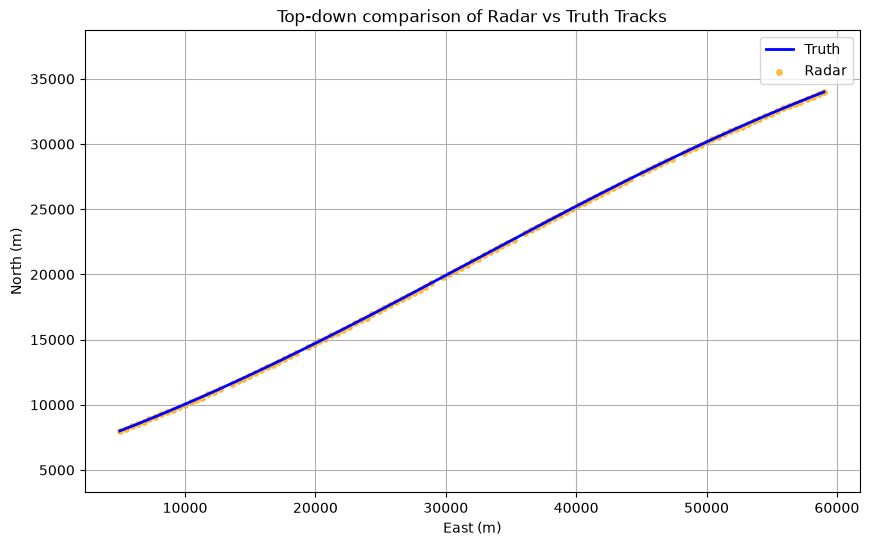

In [ ]:
#top-down comparison of our radar and truth tracks using truth/radar_clean data sets

plt.figure(figsize=(10, 6))

plt.plot(
    truth_clean["east_m"],
    truth_clean["north_m"],
    label="Truth",
    color="blue",
    linewidth=2
)

plt.scatter(
    radar_clean["east_m"],
    radar_clean["north_m"],
    label="Radar",
    color="orange",
    s=15,
    alpha=0.7
)

plt.xlabel("East (m)")
plt.ylabel("North (m)")
plt.title("Top-down comparison of Radar vs Truth Tracks")
plt.legend()
plt.grid(True)
plt.axis("equal")

plt.show()

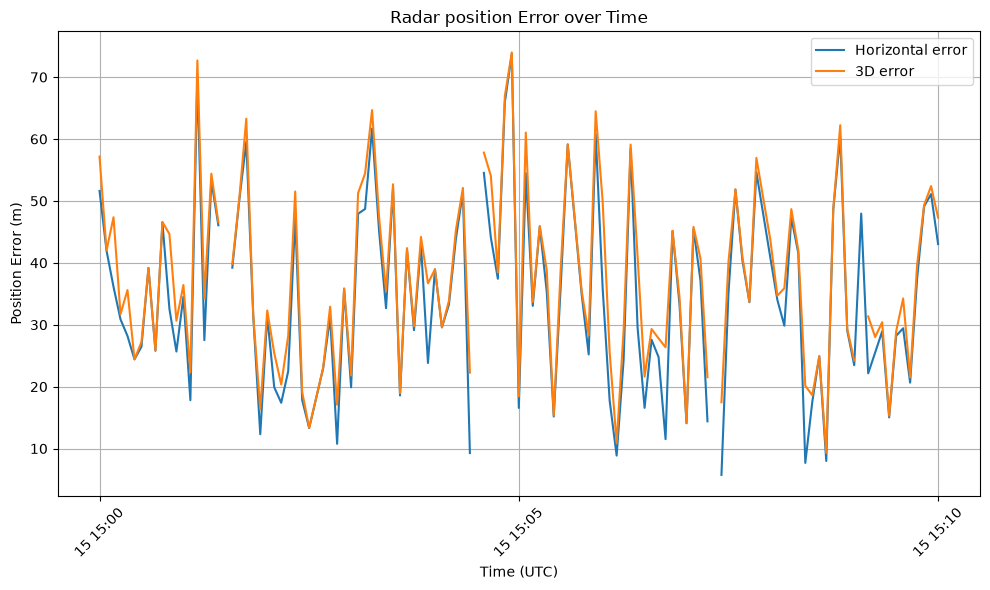

In [123]:
#Plot position error over time using comparison data set
plt.figure(figsize=(10, 6))

plt.plot(
    comparison["timestamp_utc"],
    comparison["radar_error_horizontal_m"],
    label="Horizontal error",
    linewidth=1.5
)

plt.plot(
    comparison["timestamp_utc"],
    comparison["radar_error_3d_m"],
    label="3D error",
    linewidth=1.5
)

plt.xlabel("Time (UTC)")
plt.ylabel("Position Error (m)")
plt.title("Radar position Error over Time")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

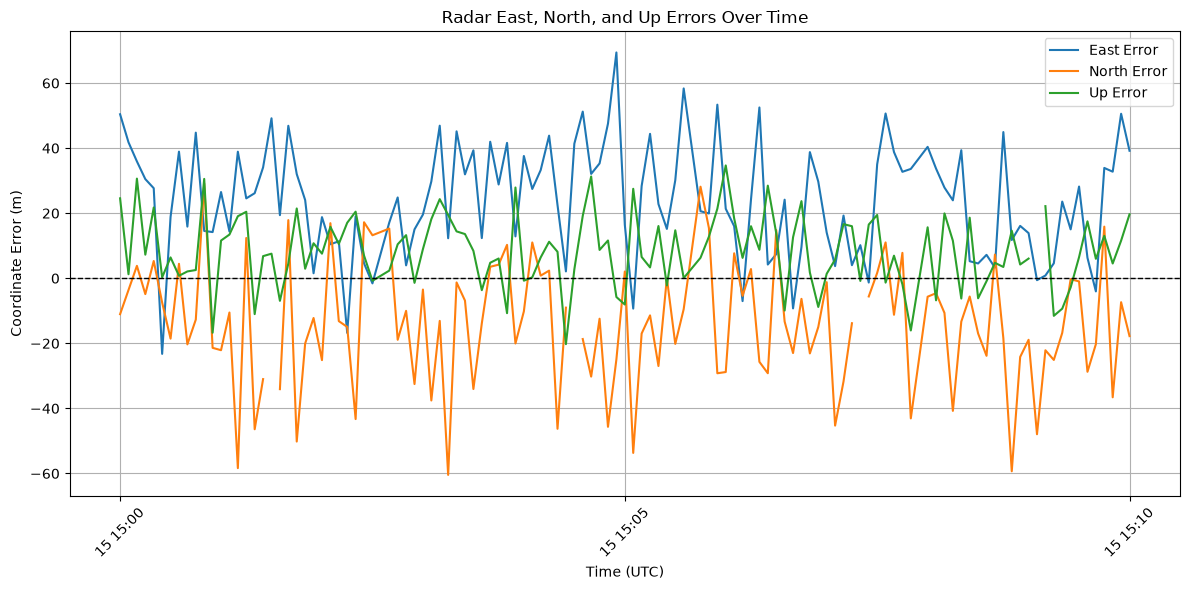

In [125]:
# Plot each direction's coordinate errors over time
plt.figure(figsize=(12, 6))

plt.plot(
    comparison["timestamp_utc"],
    comparison["radar_error_east_m"],
    label="East Error",
    linewidth=1.5
)

plt.plot(
    comparison["timestamp_utc"],
    comparison["radar_error_north_m"],
    label="North Error",
    linewidth=1.5
)

plt.plot(
    comparison["timestamp_utc"],
    comparison["radar_error_up_m"],
    label="Up Error",
    linewidth=1.5
)

# Reference line for zero error
plt.axhline(y=0, color="black", linestyle="--", linewidth=1)

plt.xlabel("Time (UTC)")
plt.ylabel("Coordinate Error (m)")
plt.title("Radar East, North, and Up Errors Over Time")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

# Analysis Overview

This project evaluated the positional accuracy of a simulated radar tracking system against a simulated truth trajectory over a 10-minute observation period.

The analysis included data cleaning, timestamp alignment through linear interpolation, position error calculations, statistical analysis, and visualization of tracking performance.

After removing three observations with duplicate timestamps, 118 radar observations remained. Of these, 60 matched truth timestamps directly, while 58 required interpolation of truth positions.

### Position Accuracy
| Metric | Horizontal | 3D |
|---|---:|---:|
| Valid observations | 115 | 114 |
| Mean error | 34.46 m | 37.34 m |
| Median error | 33.26 m | 35.72 m |
| Standard deviation | 15.00 m | 14.41 m |
| Maximum error | 73.75 m | 73.98 m |
| RMSE | 37.55 m | 40.00 m |

The simulated radar achieved a horizontal RMSE of 37.55 meters and a 3D RMSE of 40.00 meters. Including vertical position differences increased the overall measured error.

### Directional Bias 
| Coordinate | Mean Signed error |
|---|---:|
| East | +23.86 m |
| North | -13.95 m |
| Up | +8.39 m|

These results indicate that the radar generally reported target positions farther east, farther south, and higher than the corresponding truth positions. The directional error plots supported these findings.

### Data Quality and Limitations
- The analysis used generated, simulated datasets rather than measurements from an operational radar system
- Four radar observations contained missing position components. These observations were retained and excluded only from calculations requiring the missing coordinates.
- Linear interpolation estimated truth positions at radar timestamps without direct truth measurements. This assumes approximately linear target movement between consecutive truth observations.
- The analysis covered a single simulated track over a 10-minute period.

### Conclusion
The simulated radar generally followed the reference trajectory, with measurable position errors and consistent directional offsets. The analysis demonstrated a practical workflow for evaluating time-aligned tracking measurements against reference truth data, quantifying horizontal and three-dimensional position errors, identifying directional bias, and communicating performance through statistical summaries and visualizations.